# Cognitive workload as a mediator: confirmshaming and preselected options

**Research question**: *To what extent does cognitive workload (specifically NASA-TLX mental demand, temporal demand, and frustration) mediate the relationship between deceptive patterns (confirmshaming and preselected options) interface design and immediate promotional offer acceptance (task compliance) in e-commerce subscription flows?*

The three conditions are:

| Value in `condition` | Meaning (assumed) |
|---|---|
| `condition_v1` | baseline / control (**reference group**) |
| `condition_v2` | confirmshaming |
| `condition_v3` | preselected options |

**Model.** Multicategorical X with *dummy coding* relative to the baseline (D2 = v2, D3 = v3) → M = cognitive workload (one mediator at a time) → Y = `acceptance` (0/1). We estimate **relative indirect effects** (Hayes & Preacher, 2014): for each treatment j, a_j × b, where a_j is the difference in the mediator between treatment j and the baseline, and b is the effect of the mediator on acceptance, holding condition constant. In addition, v3 is compared directly with v2: (a₃ − a₂) × b.

**Methodological choices (very small sample):**
- the three mediators are tested **separately**, plus a composite index;
- binary Y → logistic regression with **Firth** penalization (robust to perfect separation); indirect effect in **log-odds**, mediator in SD units;
- inference with a **percentile bootstrap stratified by condition**, not Baron & Kenny or Sobel;
- the analysis is **exploratory**: with 3 groups and about 27 cases with NASA-TLX, there are very few observations per group.

**Contents**
1. Configuration and loading
2. Data cleaning and condition coding
3. Additional analysis (TODO: decite if we should move it as the last chapter)
4. Descriptive statistics
5. Mediator reliability and composite index
6. Total effects on acceptance
7. Mediation analysis
8. Plots
9. Summary of results and limitations

## 1. Configuration and loading

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy import stats

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)

# ---------------- CONFIGURATION ----------------
CSV_NAME = "combined_data.csv"
CONDITION_COL = "condition"         # column with v1_condition / v2 / v3
REFERENCE = "v1_condition"          # reference group (baseline)
TREATMENTS = {                      # value in CONDITION_COL -> label
    "v2_condition": "Confirmshaming",
    "v3_condition": "Preselected options",
}
REFERENCE_LABEL = "Baseline"
Y_COL = "acceptance"                # outcome: 1 = offer accepted, 0 = declined
MEDIATORS = {
    "nasa_mental_demand": "Mental demand",
    "nasa_temporal_demand": "Temporal demand",
    "nasa_frustration": "Frustration",
}
N_BOOT = 5000                       # bootstrap resamples
N_PERM = 5000                       # permutations for the chi-square tests
SEED = 2026
ALPHA = 0.05
STANDARDIZE_M = True                # mediator in standard deviation units
# ------------------------------------------------
# REUSED_WEBSITE_CASES is used to determine how to handle participants who used the website more than once (presumably for mistake or curiosity):
#
#   "max_deliberation_time" -> keep only the row with the highest
#                              deliberation_time for each participant               -> Don't lose any data, but some entry 
#                                                                                       could be mistakely refearred to a condition
#
#   "unique"                -> drop every participant who appears more than once    -> We lose some data(unethical), but we are sure that every 
#                                                                                       entry is correctly referred to a condition

#REUSED_WEBSITE_CASES = "max_deliberation_time"
REUSED_WEBSITE_CASES = "unique"

assert len(TREATMENTS) == 2, "The notebook is written for 1 baseline + 2 treatments"
rng = np.random.default_rng(SEED)

In [2]:
webpage_data = pd.read_csv("webpage_data.csv")
questionnaire_data = pd.read_csv("questionnaire_data.csv")

data = pd.merge(webpage_data, questionnaire_data, on="participant_id", how= "inner")

data = data.rename(columns={
    "  Which age group do you belong to?   ":"age_group",
    "What are you using for this test?":"device_type",
    "How often do you browse or make purchases on online shopping websites?\"": "purchase_frequency",
    "On average, how many hours per day do you spend using a computer (for work, study, or leisure)?":"computer_usage",
    "How much do you feel the website tried to pressure you into making an account/ subscribe ":"pressure_perception",
    "To what extent did you find the decline option sarcastic or mocking?":"sarcastic_mocking_extent",
    "Did you read the pop up?":"have_read_popup",
    "MENTAL DEMAND":"nasa_mental_demand",
    "TEMPORAL DEMAND":"nasa_temporal_demand",
    "FRUSTRATION LEVEL":"nasa_frustration",
    "EFFORT":"nasa_effort",
    "WILLINGNESS TO RECCOMEND":"willingness_to_recommend"
                            })
quantitative_data=data[['timestamp','participant_id','condition','action_taken','deliberation_time_sec','email_entered','checkboxes_checked','nasa_mental_demand','nasa_temporal_demand','nasa_effort','nasa_frustration','willingness_to_recommend','age_group','device_type','purchase_frequency','computer_usage','pressure_perception','sarcastic_mocking_extent','have_read_popup', 'is_pilot']]
acceptance_mapping = {
    "clicked_submit_decline": 0,
    "clicked_submit_accept": 1,
    "clicked_decline_text_link": 0,
    #"clicked_close_x_button": 0 #: delete it if we decide to delete pilot testings -> This is not a case anymore
}

quantitative_data = quantitative_data[quantitative_data['is_pilot'] != 1].copy()
quantitative_data = quantitative_data.drop(columns=['is_pilot'])

quantitative_data["acceptance"] = quantitative_data["action_taken"].map(acceptance_mapping).astype("Int64")

if REUSED_WEBSITE_CASES == "max_deliberation_time":
    quantitative_data = quantitative_data[quantitative_data['deliberation_time_sec'] == quantitative_data.groupby('participant_id')['deliberation_time_sec'].transform('max')]
elif REUSED_WEBSITE_CASES == "unique":
    quantitative_data = quantitative_data[~quantitative_data.duplicated(subset='participant_id', keep=False)]
#quantitative_data.info()

quantitative_data.to_csv(CSV_NAME, index=False)

In [3]:
if CSV_NAME.lower().endswith((".xlsx", ".xls")):
    raw = pd.read_excel(CSV_NAME)
else:
    raw = pd.read_csv(CSV_NAME)

print("Shape:", raw.shape)
raw.info()
raw.head()

Shape: (27, 20)
<class 'pandas.DataFrame'>
RangeIndex: 27 entries, 0 to 26
Data columns (total 20 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   timestamp                 27 non-null     str    
 1   participant_id            27 non-null     str    
 2   condition                 27 non-null     str    
 3   action_taken              27 non-null     str    
 4   deliberation_time_sec     27 non-null     float64
 5   email_entered             27 non-null     bool   
 6   checkboxes_checked        27 non-null     str    
 7   nasa_mental_demand        26 non-null     float64
 8   nasa_temporal_demand      26 non-null     float64
 9   nasa_effort               26 non-null     float64
 10  nasa_frustration          26 non-null     float64
 11  willingness_to_recommend  26 non-null     float64
 12  age_group                 27 non-null     str    
 13  device_type               27 non-null     str    
 14  purchas

,timestamp,participant_id,condition,action_taken,deliberation_time_sec,email_entered,checkboxes_checked,nasa_mental_demand,nasa_temporal_demand,nasa_effort,nasa_frustration,willingness_to_recommend,age_group,device_type,purchase_frequency,computer_usage,pressure_perception,sarcastic_mocking_extent,have_read_popup,acceptance
0,2026-11-13T17:06:29.071Z,P_SAZZ6K05,v3_condition,clicked_decline_text_link,9.62,False,none,4.0,2.0,3.0,4.0,5.0,22-26,Smartphone,Less than once per month,5-8 hours,5.0,6.0,Yes,0
1,2026-11-13T17:24:18.428Z,P_OOO1335B,v2_condition,clicked_decline_text_link,2.06,False,2/2 checked,3.0,2.0,2.0,2.0,8.0,27-32,Smartphone,Less than once per month,5-8 hours,2.0,1.0,Yes,0
2,2026-11-13T17:49:42.801Z,P_L2MS60HV,v3_condition,clicked_submit_accept,10.88,False,none,4.0,9.0,3.0,4.0,5.0,22-26,Smartphone,Less than once per month,More than 8 hours,7.0,7.0,Yes,1
3,2026-11-13T18:00:01.181Z,P_Z5BWJHR0,v1_condition,clicked_submit_decline,9.11,True,none,6.0,4.0,6.0,8.0,1.0,22-26,Computer / Laptop,Less than once per month,5-8 hours,6.0,1.0,Yes,0
4,2026-11-13T18:01:12.161Z,P_YL01FHZU,v3_condition,clicked_decline_text_link,9.88,False,none,5.0,2.0,3.0,5.0,5.0,22-26,Computer / Laptop,Less than once per month,5-8 hours,6.0,5.0,Yes,0


## 2. Data cleaning and condition coding

In [4]:
df = raw.copy()

# 2) duplicate participant_ids (keep the first response in time order)
df = df.sort_values("timestamp")
n_dup = int(df["participant_id"].duplicated().sum())
print(f"Duplicate participant_id rows excluded: {n_dup}")
df = df[~df["participant_id"].duplicated()].copy()

# 3) conditions
# 3a. Show what is there
print("\nValues of", CONDITION_COL)
print(df[CONDITION_COL].value_counts(dropna=False))
# 3b. Check that all expected conditions are present
expected = [REFERENCE] + list(TREATMENTS)
present = set(df[CONDITION_COL].dropna().unique())
absent = [l for l in expected if l not in present]
if absent:
    raise ValueError(f"Expected levels not found in '{CONDITION_COL}': {absent}. Present: {sorted(present)}")
# 3c. Handle unexpected values
extra = present - set(expected)
if extra:
    print(f"\nWARNING: unexpected levels, rows excluded: {sorted(extra)}")
    df = df[df[CONDITION_COL].isin(expected)].copy()

# 3d. Give readable names
LABELS = {REFERENCE: REFERENCE_LABEL, **TREATMENTS}
cond_order = [LABELS[k] for k in expected]
df["cond"] = pd.Categorical(df[CONDITION_COL].map(LABELS), categories=cond_order, ordered=True)

# 3e. Create the dummies
# dummy coding relative to the baseline: D_condition_v2 = 1 if confirmshaming, D_condition_v3 = 1 if Preselected options
# (statistical calculations need dummies, i.e. numeric values to work on)
TREAT_KEYS = list(TREATMENTS)
D_COLS = []
for k in TREAT_KEYS:
    col = f"D_{k}"
    df[col] = (df[CONDITION_COL] == k).astype(int)
    D_COLS.append(col)
print(f"\nCoding: baseline = '{REFERENCE}'; dummies = {D_COLS}")

# 4) setup for outcome Y
df["Y"] = pd.to_numeric(df[Y_COL], errors="coerce").astype(float)
assert set(df["Y"].dropna().unique()) <= {0.0, 1.0}, "acceptance must be 0/1"
print("\nConsistency of acceptance vs action_taken, by condition")
print("(check that 'acceptance' has the same meaning in the three conditions, especially in v3):")
print(pd.crosstab([df["cond"], df["action_taken"]], df["Y"]))

# 5) numeric mediators
for c in MEDIATORS:
    df[c] = pd.to_numeric(df[c], errors="coerce")
print("\nMediator ranges (check the NASA-TLX scale, e.g. 0-100 or 1-21):")
df[list(MEDIATORS)].describe().loc[["count", "min", "max"]]

Duplicate participant_id rows excluded: 0

Values of condition
condition
v1_condition    13
v3_condition     8
v2_condition     6
Name: count, dtype: int64

Coding: baseline = 'v1_condition'; dummies = ['D_v2_condition', 'D_v3_condition']

Consistency of acceptance vs action_taken, by condition
(check that 'acceptance' has the same meaning in the three conditions, especially in v3):
Y                                              0.0  1.0
cond                action_taken                       
Baseline            clicked_submit_accept        0    1
                    clicked_submit_decline      12    0
Confirmshaming      clicked_decline_text_link    5    0
                    clicked_submit_accept        0    1
Preselected options clicked_decline_text_link    5    0
                    clicked_submit_accept        0    3

Mediator ranges (check the NASA-TLX scale, e.g. 0-100 or 1-21):


,nasa_mental_demand,nasa_temporal_demand,nasa_frustration
count,26.0,26.0,26.0
min,1.0,1.0,1.0
max,7.0,10.0,10.0


## 3. Additional analysis

At the start of the testing phase, filling in the selected NASA-TLX dimensions in the questionnaire was not mandatory; it was made mandatory later to collect more data, given the small number of participants. For this reason, some NASA-TLX scores are missing.

Looking at the data, a hypothesis emerged: those who did not respond may not be a “random” group. For example, someone may have rushed through the process because of the stress caused by the condition they saw. We check two things:
1. are the missing values distributed similarly across the three conditions?
2. did those who did not respond take less time to decide (`deliberation_time_sec`) than those who did?

In [5]:
med_cols = list(MEDIATORS)
df["nasa_missing"] = df[med_cols].isna().any(axis=1)   # True = at least one NASA-TLX score is missing

# 1) are the missing values distributed similarly across conditions?
miss_cond = df.groupby("cond", observed=True)["nasa_missing"].agg(n="size", missing="sum", percentage="mean")
miss_cond["percentage"] = (miss_cond["percentage"] * 100).round(0)
print("Missing NASA-TLX by condition:")
print(miss_cond)

# 2) did those who did not respond decide faster?
t_ok = df.loc[~df["nasa_missing"], "deliberation_time_sec"].dropna()
t_miss = df.loc[df["nasa_missing"], "deliberation_time_sec"].dropna()
print("\nDeliberation time (seconds):")
print(f"  responded      (n = {len(t_ok)}):   median = {t_ok.median():.1f}")
print(f"  did not respond (n = {len(t_miss)}):   median = {t_miss.median():.1f}")
if len(t_ok) > 0 and len(t_miss) > 0:
    p_t = stats.mannwhitneyu(t_miss, t_ok, alternative="two-sided").pvalue
    print(f"  Mann-Whitney test: p = {p_t:.3f}")

Missing NASA-TLX by condition:
                      n  missing  percentage
cond                                        
Baseline             13        1         8.0
Confirmshaming        6        0         0.0
Preselected options   8        0         0.0

Deliberation time (seconds):
  responded      (n = 26):   median = 8.8
  did not respond (n = 1):   median = 19.3
  Mann-Whitney test: p = 0.296


## 4. Descriptive statistics

In [6]:
desc = df.groupby("cond", observed=True).agg(
    n=("Y", "size"),
    mean_acceptance=("Y", "mean"),
    **{f"{c}_mean": (c, "mean") for c in med_cols},
    **{f"{c}_sd": (c, "std") for c in med_cols},
    **{f"{c}_n": (c, "count") for c in med_cols},
).T
desc.round(2)

cond,Baseline,Confirmshaming,Preselected options
n,13.00,6.00,8.00
mean_acceptance,0.08,0.17,0.38
nasa_mental_demand_mean,3.58,3.83,4.62
nasa_temporal_demand_mean,4.67,6.67,5.38
nasa_frustration_mean,5.75,5.67,5.88
nasa_mental_demand_sd,1.78,2.56,1.30
nasa_temporal_demand_sd,2.93,3.67,3.25
nasa_frustration_sd,2.99,3.39,2.17
nasa_mental_demand_n,12.00,6.00,8.00
nasa_temporal_demand_n,12.00,6.00,8.00


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 27 entries, 0 to 26
Data columns (total 25 columns):
 #   Column                    Non-Null Count  Dtype   
---  ------                    --------------  -----   
 0   timestamp                 27 non-null     str     
 1   participant_id            27 non-null     str     
 2   condition                 27 non-null     str     
 3   action_taken              27 non-null     str     
 4   deliberation_time_sec     27 non-null     float64 
 5   email_entered             27 non-null     bool    
 6   checkboxes_checked        27 non-null     str     
 7   nasa_mental_demand        26 non-null     float64 
 8   nasa_temporal_demand      26 non-null     float64 
 9   nasa_effort               26 non-null     float64 
 10  nasa_frustration          26 non-null     float64 
 11  willingness_to_recommend  26 non-null     float64 
 12  age_group                 27 non-null     str     
 13  device_type               27 non-null     str     
 14  purchas

## 5. Mediator reliability and composite index

We assess whether the three mediators are correlated enough to be combined into a single cognitive workload index. If Cronbach's alpha is low (roughly below 0.6), the composite index is not justified: keep the three mediators separate and treat the `composite` rows as purely descriptive.

In [8]:
cc = df.dropna(subset=med_cols)
print(f"Cases with all three mediators: {len(cc)}")
print("\nSpearman correlations:")
print(cc[med_cols].corr(method="spearman").round(2))

def cronbach_alpha(d):
    k = d.shape[1]
    return k / (k - 1) * (1 - d.var(ddof=1).sum() / d.sum(axis=1).var(ddof=1))

z = (cc[med_cols] - cc[med_cols].mean()) / cc[med_cols].std(ddof=1)
print(f"\nCronbach alpha (standardized items): {cronbach_alpha(z):.2f}")

# composite index: mean of the z-scores of the three mediators
mu = df[med_cols].mean()
sd = df[med_cols].std(ddof=1)
df["workload_composite"] = ((df[med_cols] - mu) / sd).mean(axis=1, skipna=False)

MEDIATORS_ALL = dict(MEDIATORS)
MEDIATORS_ALL["workload_composite"] = "Composite workload (z-mean)"

Cases with all three mediators: 26

Spearman correlations:
                      nasa_mental_demand  nasa_temporal_demand  nasa_frustration
nasa_mental_demand                  1.00                  0.23              0.23
nasa_temporal_demand                0.23                  1.00              0.70
nasa_frustration                    0.23                  0.70              1.00

Cronbach alpha (standardized items): 0.68


## 6. Total effects on acceptance

Effect of each treatment relative to the baseline on acceptance, without mediators (c₂ and c₃, in log-odds, with Firth), plus Fisher's exact tests for each comparison with the baseline and an omnibus permutation test.

In [9]:
def chi2_stat(g, f):
    """Chi-square of a groups x (0/1) table; g, f integer arrays."""
    obs = np.zeros((g.max() + 1, 2))
    np.add.at(obs, (g, f), 1)
    exp = obs.sum(1, keepdims=True) * obs.sum(0, keepdims=True) / obs.sum()
    with np.errstate(divide="ignore", invalid="ignore"):
        return np.nansum((obs - exp) ** 2 / exp)

def perm_chi2_p(group, flag, n_perm=N_PERM):
    g = pd.factorize(pd.Series(group).astype(str))[0]
    f = np.asarray(flag).astype(int)
    if len(np.unique(g)) < 2 or len(np.unique(f)) < 2:
        return np.nan
    obs = chi2_stat(g, f)
    cnt = sum(chi2_stat(g, rng.permutation(f)) >= obs - 1e-12 for _ in range(n_perm))
    return (1 + cnt) / (n_perm + 1)

def firth_logit(X, y, max_iter=300, tol=1e-8):
    """Logistic regression with Firth penalization (robust to perfect separation)."""
    X = np.asarray(X, float)
    y = np.asarray(y, float)
    beta = np.zeros(X.shape[1])
    for _ in range(max_iter):
        eta = np.clip(X @ beta, -30, 30)
        p = 1 / (1 + np.exp(-eta))
        w = p * (1 - p)
        info = X.T @ (X * w[:, None])
        info_inv = np.linalg.pinv(info)
        h = w * np.einsum("ij,jk,ik->i", X, info_inv, X)
        score = X.T @ (y - p + h * (0.5 - p))
        step = info_inv @ score
        mx = np.abs(step).max()
        if mx > 5:
            step *= 5 / mx
        beta = beta + step
        if np.abs(step).max() < tol:
            break
    return beta

def wald_logit(X, y):
    """Standard logit (statsmodels) for Wald standard errors; None if it does not converge."""
    try:
        with warnings.catch_warnings():
            warnings.simplefilter("error")
            return sm.Logit(y, X).fit(disp=0)
    except Exception:
        return None


d0 = df.dropna(subset=["Y"])
tab = pd.crosstab(d0["cond"], d0["Y"])
print("Condition x acceptance table:")
print(tab)
print("\nAcceptance rate by condition:")
print(d0.groupby("cond", observed=True)["Y"].mean().round(3))
print(f"\nOmnibus permutation test (chi-square): p = {perm_chi2_p(d0['cond'], d0['Y']):.3f}")

# Fisher: each treatment vs baseline (OR = acceptance odds treatment / baseline)
print()
for k in TREAT_KEYS:
    sub = d0[d0[CONDITION_COL].isin([REFERENCE, k])]
    try:
        t = pd.crosstab(sub[f"D_{k}"], sub["Y"]).loc[[1, 0], [1, 0]]
        odds, p_f = stats.fisher_exact(t)
        print(f"Fisher {LABELS[k]} vs {REFERENCE_LABEL}: OR = {odds:.2f}, p = {p_f:.3f}")
    except KeyError:
        print(f"Fisher {LABELS[k]} vs {REFERENCE_LABEL}: cannot be computed (empty cells)")

# total effects c_j (Firth) and standard logit
Xc = np.column_stack([np.ones(len(d0)), d0[D_COLS].to_numpy(float)])
yc = d0["Y"].to_numpy(float)
beta_c = firth_logit(Xc, yc)
res_c = wald_logit(Xc, yc)
c_total = {}
print()
for j, k in enumerate(TREAT_KEYS):
    c_total[k] = beta_c[1 + j]
    msg = f"Total effect c ({LABELS[k]} vs {REFERENCE_LABEL}), Firth: {c_total[k]:.3f} log-odds (OR = {np.exp(c_total[k]):.2f})"
    if res_c is not None:
        msg += f"; standard logit p (Wald) = {res_c.pvalues[1 + j]:.3f}"
    print(msg)
if res_c is None:
    print("Standard logit does not converge (probable separation): use Firth/Fisher.")

Condition x acceptance table:
Y                    0.0  1.0
cond                         
Baseline              12    1
Confirmshaming         5    1
Preselected options    5    3

Acceptance rate by condition:
cond
Baseline               0.077
Confirmshaming         0.167
Preselected options    0.375
Name: Y, dtype: float64

Omnibus permutation test (chi-square): p = 0.264

Fisher Confirmshaming vs Baseline: OR = 2.40, p = 1.000
Fisher Preselected options vs Baseline: OR = 7.20, p = 0.253

Total effect c (Confirmshaming vs Baseline), Firth: 0.821 log-odds (OR = 2.27); standard logit p (Wald) = 0.562
Total effect c (Preselected options vs Baseline), Firth: 1.668 log-odds (OR = 5.30); standard logit p (Wald) = 0.121


| Term | Meaning |
|---|---|
| **Total effect (c)** | The overall effect of a design on acceptance, ignoring the mediator. Goal of this section, starting point for mediation. |
| **Logistic regression** | A model for yes/no outcomes: it estimates how the probability of "yes" changes with one or more variables. |
| **Odds ratio (OR)** | The ratio between the odds of two groups. OR = 1: no difference; OR > 1: more acceptance than the comparison group; OR < 1: less. |
| **Log-odds** | The logarithm of the odds, the unit in which logistic regression reports effects. 0 = no effect, positive = more acceptance, negative = less. Convert to OR with exp(value). |
| **Firth regression** | A logistic regression with a small penalty that stabilizes estimates in small samples and handles perfect separation. |
| **Perfect separation** | A variable predicts the outcome without any error (e.g., everyone in a group accepts). Standard logistic regression then fails to converge or returns extreme values. |
| **Wald test** | Tests whether a single regression coefficient differs from zero. Provides the p-value for c and b. |
| **Fisher's exact test** | Compares acceptance rates between two groups in a 2x2 table. "Exact" means reliable even with very few cases. It also returns an odds ratio. |
| **Chi-square statistic** | Measures how far a table of counts is from the table expected if there were no relationship. |
| **Permutation test** | Reshuffles labels thousands of times to see how often chance alone produces a difference as large as the observed one. Makes no assumptions about the data's shape. |
| **Omnibus test** | A test of all groups together ("is there a difference somewhere?"). It does not say which groups differ. |
| **Why Fisher's OR and Firth's OR differ** | Fisher's OR comes from the raw table; Firth's applies a small-sample correction that slightly shrinks extreme estimates. Cite Firth for the estimate and Fisher for the exact p-value. |


## 7. Mediation analysis

For each mediator M, on the cases where M is available:
- **path a** (per treatment j): difference in M between treatment j and the baseline (in SD if `STANDARDIZE_M`), with Welch's test, Mann-Whitney and Hedges' g; plus a Kruskal-Wallis test across the three conditions;
- **path b and c′**: logistic `Y ~ D2 + D3 + M` (Firth for the estimates; Wald from the standard logit when it converges);
- **relative indirect effects** a_j × b (log-odds) and the v3 vs v2 comparison = (a₃ − a₂) × b, with a percentile bootstrap stratified by condition (`N_BOOT` resamples).

We report the 95% CI and the CI corrected with Bonferroni over the number of main tests (single mediators × treatments). If the CI **excludes zero** there is evidence of mediation; if it includes zero the result is inconclusive (with this N it does not mean “no effect”). 

In [10]:
def hedges_g(a, b):
    n1, n2 = len(a), len(b)
    sp = np.sqrt(((n1 - 1) * a.var(ddof=1) + (n2 - 1) * b.var(ddof=1)) / (n1 + n2 - 2))
    return (a.mean() - b.mean()) / sp * (1 - 3 / (4 * (n1 + n2) - 9))


def paths_once(D, m, y):
    """a_j (diff. vs baseline), b, c'_j from Y ~ D + M (Firth)."""
    ref = D.sum(axis=1) == 0
    a = np.array([m[D[:, j] == 1].mean() - m[ref].mean() for j in range(D.shape[1])])
    beta = firth_logit(np.column_stack([np.ones(len(y)), D, m]), y)
    K = D.shape[1]
    return a, beta[-1], beta[1:1 + K]


def indirect_vec(a, b):
    """[a2*b, a3*b, (a3-a2)*b]"""
    return np.array([a[0] * b, a[1] * b, (a[1] - a[0]) * b])


CONTRASTS = [f"{LABELS[k]} vs {REFERENCE_LABEL}" for k in TREAT_KEYS] + \
            [f"{LABELS[TREAT_KEYS[1]]} vs {LABELS[TREAT_KEYS[0]]}"]


def run_mediation(mcol, label, data, n_boot, n_tests):
    d = data.dropna(subset=["Y", mcol, "cond"])
    D = d[D_COLS].to_numpy(float)
    y = d["Y"].to_numpy(float)
    m_raw = d[mcol].to_numpy(float)
    cond = d[CONDITION_COL].to_numpy()
    sizes = {lv: int((cond == lv).sum()) for lv in expected}
    if min(sizes.values()) < 2 or len(np.unique(y)) < 2 or m_raw.std(ddof=1) == 0:
        print(f"Skipped {label}: insufficient data (n per group: {sizes}) or zero variance")
        return None
    m = (m_raw - m_raw.mean()) / m_raw.std(ddof=1) if STANDARDIZE_M else m_raw

    a, b, c_prime = paths_once(D, m, y)
    ind = indirect_vec(a, b)

    # path a: test for each treatment vs baseline + omnibus
    ref_vals = m_raw[cond == REFERENCE]
    groups = [m_raw[cond == lv] for lv in expected]
    p_kw = stats.kruskal(*groups).pvalue
    tests = []
    for k in TREAT_KEYS:
        v = m_raw[cond == k]
        tests.append((stats.ttest_ind(v, ref_vals, equal_var=False).pvalue,
                      stats.mannwhitneyu(v, ref_vals, alternative="two-sided").pvalue,
                      hedges_g(v, ref_vals)))
    # v3 vs v2 contrast
    v3, v2 = m_raw[cond == TREAT_KEYS[1]], m_raw[cond == TREAT_KEYS[0]]
    tests.append((stats.ttest_ind(v3, v2, equal_var=False).pvalue,
                  stats.mannwhitneyu(v3, v2, alternative="two-sided").pvalue,
                  hedges_g(v3, v2)))

    # Wald for path b
    res = wald_logit(np.column_stack([np.ones(len(y)), D, m]), y)
    p_b = res.pvalues[-1] if res is not None else np.nan

    # bootstrap stratified by condition
    idx = [np.where(cond == lv)[0] for lv in expected]
    boot = np.empty((n_boot, 3))
    for i in range(n_boot):
        s = np.concatenate([rng.choice(ix, len(ix)) for ix in idx])
        a_s, b_s, _ = paths_once(D[s], m[s], y[s])
        boot[i] = indirect_vec(a_s, b_s)
    lo, hi = np.percentile(boot, [100 * ALPHA / 2, 100 * (1 - ALPHA / 2)], axis=0)
    a_adj = ALPHA / n_tests
    lo_b, hi_b = np.percentile(boot, [100 * a_adj / 2, 100 * (1 - a_adj / 2)], axis=0)

    c_pr = np.array([c_prime[0], c_prime[1], c_prime[1] - c_prime[0]])
    rows = []
    for i, contrast in enumerate(CONTRASTS):
        a_i = a[i] if i < 2 else a[1] - a[0]
        rows.append(dict(
            mediator=label, contrast=contrast, n=len(d),
            n_groups="/".join(str(sizes[lv]) for lv in expected),
            a=a_i, g_hedges=tests[i][2], p_a_welch=tests[i][0], p_a_mwu=tests[i][1], p_a_kruskal=p_kw,
            b_logodds=b, OR_b=np.exp(b), p_b_wald=p_b,
            c_prime=c_pr[i], indirect_ab=ind[i],
            ci_lo=lo[i], ci_hi=hi[i], ci_lo_adj=lo_b[i], ci_hi_adj=hi_b[i],
            mediation_ci95=bool(lo[i] > 0 or hi[i] < 0),
            mediation_ci_adj=bool(lo_b[i] > 0 or hi_b[i] < 0),
        ))
    return rows


n_tests = len(MEDIATORS) * len(TREATMENTS)
all_rows = []
for col, label in MEDIATORS_ALL.items():
    rows = run_mediation(col, label, df, N_BOOT, n_tests=n_tests)
    if rows:
        all_rows.extend(rows)

res_tab = pd.DataFrame(all_rows).set_index(["mediator", "contrast"])
res_tab.round(3)

n n_groups      a  g_hedges  p_a_welch  p_a_mwu  p_a_kruskal  \
mediator                    contrast                                                                                               
Mental demand               Confirmshaming vs Baseline             26   12/6/8  0.136     0.116      0.836    0.886        0.322   
                            Preselected options vs Baseline        26   12/6/8  0.565     0.619      0.149    0.158        0.322   
                            Preselected options vs Confirmshaming  26   12/6/8  0.429     0.384      0.511    0.323        0.322   
Temporal demand             Confirmshaming vs Baseline             26   12/6/8  0.630     0.599      0.277    0.254        0.516   
                            Preselected options vs Baseline        26   12/6/8  0.223     0.222      0.627    0.696        0.516   
                            Preselected options vs Confirmshaming  26   12/6/8 -0.407    -0.353      0.509    0.599        0.516   
Frustration                 Confirmshaming vs Baseline             26   12/6/8 -0.030    -0.025      0.960    0.962        0.999   
                            Preselected options vs Baseline        26   12/6/8  0.046     0.044      0.915    1.000        0.999   
                            Preselected options vs Confirmshaming  26   12/6/8  0.076     0.071      0.898    1.000        0.999   
Composite workload (z-mean) Confirmshaming vs Baseline             26   12/6/8  0.313     0.276      0.628    0.494        0.589   
                            Preselected options vs Baseline        26   12/6/8  0.355     0.375      0.401    0.384        0.589   
                            Preselected options vs Confirmshaming  26   12/6/8  0.042     0.035      0.949    1.000        0.589   

                                                                   b_logodds   OR_b  p_b_wald  c_prime  indirect_ab  ci_lo  ci_hi  \
mediator                    contrast                                                                                                
Mental demand               Confirmshaming vs Baseline                 0.119  1.127     0.823    0.736        0.016 -0.882  1.254   
                            Preselected options vs Baseline            0.119  1.127     0.823    1.449        0.067 -1.933  0.863   
                            Preselected options vs Confirmshaming      0.119  1.127     0.823    0.713        0.051 -2.237  0.993   
Temporal demand             Confirmshaming vs Baseline                 1.265  3.543     0.054   -0.081        0.797 -0.836  3.121   
                            Preselected options vs Baseline            1.265  3.543     0.054    1.621        0.282 -1.562  1.426   
                            Preselected options vs Confirmshaming      1.265  3.543     0.054    1.702       -0.515 -3.422  1.065   
Frustration                 Confirmshaming vs Baseline                 0.580  1.785     0.240    0.742       -0.018 -1.528  1.048   
                            Preselected options vs Baseline            0.580  1.785     0.240    1.597        0.026 -0.669  0.982   
                            Preselected options vs Confirmshaming      0.580  1.785     0.240    0.855        0.044 -0.894  1.615   
Composite workload (z-mean) Confirmshaming vs Baseline                 0.798  2.221     0.142    0.381        0.250 -1.337  2.918   
                            Preselected options vs Baseline            0.798  2.221     0.142    1.389        0.284 -0.714  1.964   
                            Preselected options vs Confirmshaming      0.798  2.221     0.142    1.008        0.033 -2.274  1.856   

                                                                   ci_lo_adj  ci_hi_adj  mediation_ci95  mediation_ci_adj  
mediator                    contrast                                                                                       
Mental demand               Confirmshaming vs Baseline                -2.666      2.477           False     

| Term | Simple meaning |
|---|---|
| **Mediation** | The design influences the outcome *through* the mediator: X → M → Y. |
| **Path a** | Effect of X on the mediator (does the design change the score?). |
| **Path b** | Effect of the mediator on Y, holding the condition constant (does the score change acceptance?). |
| **Direct effect (c′)** | The effect of X on Y that remains after accounting for the mediator. |
| **Indirect effect (a × b)** | The part of the effect that passes through the mediator, obtained by multiplying a and b. |
| **Relative indirect effect** | The indirect effect of one treatment *compared with the baseline* (or of one treatment compared with another). Used when X has more than two groups. |
| **Suppression / inconsistent mediation** | The indirect and direct effects have opposite signs: the mediator works against the direct effect. A "proportion mediated" is then meaningless. |
| **Hedges' g** | An effect size for the difference between two groups: mean difference divided by the pooled variability, with a small-sample correction. Rough guide: 0.2 small, 0.5 medium, 0.8 large. |
| **Welch's t-test** | Compares the means of two groups without assuming equal variability. |
| **Kruskal-Wallis test** | Like Mann-Whitney, but for three or more groups. Says whether at least one group differs, not which one. |
| **Bootstrap** | Repeatedly drawing participants (with replacement) from the sample to build many simulated samples and see how much the estimate varies. Needed because a × b has no simple formula for its uncertainty. |
| **Stratified bootstrap** | Resampling separately within each condition, so group sizes are preserved. |
| **Percentile confidence interval** | The interval between the 2.5th and 97.5th percentiles of the bootstrap estimates. |
| **95% confidence interval (CI)** | A range of plausible values for the effect. In mediation: if it **excludes zero**, there is evidence of mediation; if it **includes zero**, the result is inconclusive (with little data, this does not mean "no effect"). |
| **Bonferroni correction** | Running several tests increases the chance of false positives. The threshold (0.05) is divided by the number of main tests (here 6: 3 mediators x 2 treatments), producing a wider, more conservative interval. |
| **Multiple testing** | Performing many tests on the same data, which inflates the false-positive risk unless corrected. |
| **Exploratory analysis** | Analysis that generates hypotheses rather than confirming them; results are indications, not proof. |


**How to read the table** (the `Composite` rows are an additional analysis and are not included in the correction):
- `n_groups`: cases per condition in the order baseline / v2 / v3 (see how small they are);
- `a`: mean difference in the mediator (first group − second, in SD); `p_a_kruskal` is the omnibus test across the three conditions;
- `b_logodds` / `OR_b`: effect of the mediator on acceptance, holding condition constant, per 1 SD (it is the same for all contrasts of the same mediator);
- `c_prime`: direct effect (log-odds) controlling for the mediator;
- `indirect_ab`: relative indirect effect (log-odds), with bootstrap CI at 95% (`ci_lo`, `ci_hi`) and corrected (`ci_lo_adj`, `ci_hi_adj`).
- If `indirect_ab` has the **opposite sign** to `c_prime`, this is *inconsistent mediation* or *suppression*: the “proportion mediated” is not interpretable.

run_mediation:
Selects the people with acceptance, score and condition available (about 25).
Checks that the analysis makes sense: if a group has fewer than 2 people, if everyone gave the same response, or if the score is identical for everyone, it skips that score and reports it.
Standardizes the score in standard deviations.
Estimates a, b and c′ with paths_once and computes the indirect effect a × b with indirect_vec.
Tests path a (does the design change the score?) with Welch, Mann-Whitney, Kruskal-Wallis and Hedges' g.
Computes the p-value of b with standard regression (if it converges).
Runs the bootstrap: 5000 times it resamples people within each condition and recomputes a × b.
Derives the 95% confidence intervals and the more conservative ones with Bonferroni.
Packs everything into a list of three rows (one per comparison: v2 vs baseline, v3 vs baseline, v3 vs v2)

## 8. Plots

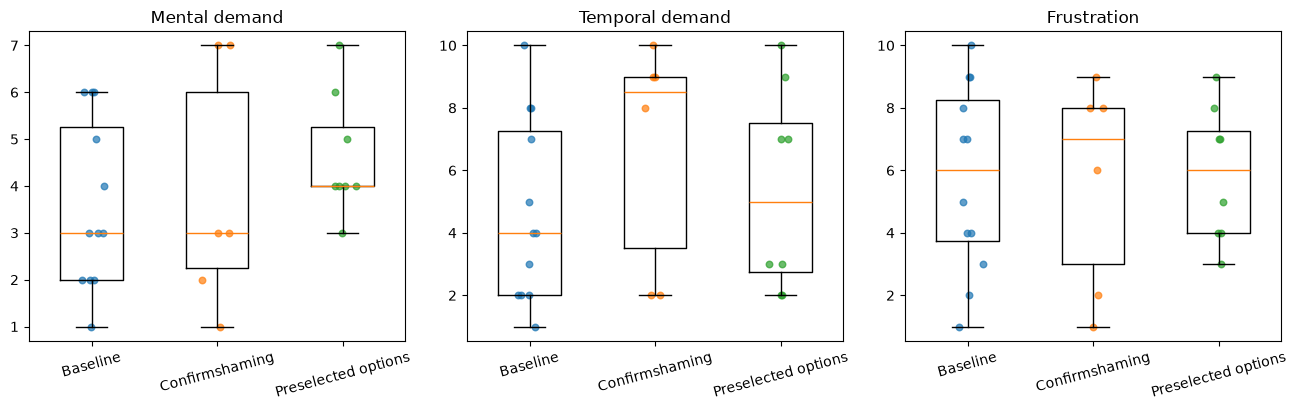

In [11]:
colors = {lv: f"C{i}" for i, lv in enumerate(cond_order)}
fig, axes = plt.subplots(1, len(MEDIATORS), figsize=(4.4 * len(MEDIATORS), 4.2))
for ax, (col, label) in zip(np.atleast_1d(axes), MEDIATORS.items()):
    data = [df.loc[df["cond"] == lv, col].dropna() for lv in cond_order]
    ax.boxplot(data, widths=0.5, showfliers=False)
    for i, (lv, vals) in enumerate(zip(cond_order, data), start=1):
        ax.scatter(np.full(len(vals), i) + rng.normal(0, 0.05, len(vals)), vals,
                   alpha=0.7, s=22, color=colors[lv])
    ax.set_xticks(range(1, len(cond_order) + 1))
    ax.set_xticklabels(cond_order, rotation=15)
    ax.set_title(label)
plt.tight_layout()
plt.show()

How to read it. There are three panels, one per score, and in each a “box” per condition:

the line inside the box is the median;
the box contains the middle 50% of people;
the whiskers show the typical range of values;
the colored dots are the individual participants.

If the box of one condition sits clearly higher than the others, that design tends to raise the score. With few cases it is worth looking at the dots too: a box can look high because of just two people.

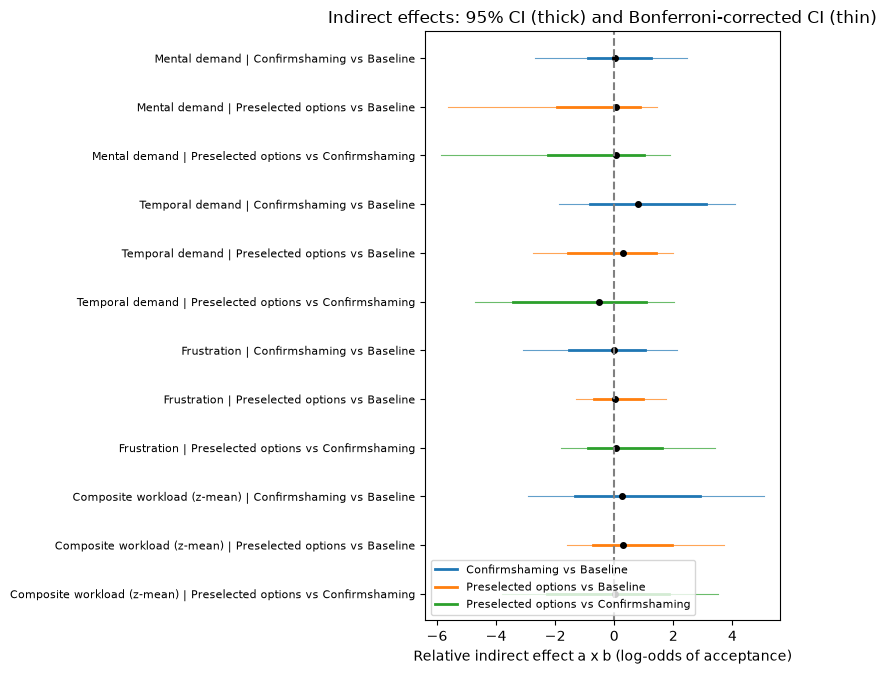

In [12]:
rows_plot = res_tab.reset_index()
fig, ax = plt.subplots(figsize=(8, 0.42 * len(rows_plot) + 1.8))
ys = np.arange(len(rows_plot))[::-1]
contrast_colors = {c: f"C{i}" for i, c in enumerate(CONTRASTS)}
for yv, (_, r) in zip(ys, rows_plot.iterrows()):
    col = contrast_colors[r["contrast"]]
    ax.plot([r["ci_lo"], r["ci_hi"]], [yv, yv], lw=2, color=col)
    ax.plot([r["ci_lo_adj"], r["ci_hi_adj"]], [yv, yv], lw=0.8, color=col, alpha=0.7)
    ax.plot(r["indirect_ab"], yv, "o", color="k", ms=4)
ax.axvline(0, color="grey", ls="--")
ax.set_yticks(ys)
ax.set_yticklabels([f"{m} | {c}" for m, c in zip(rows_plot["mediator"], rows_plot["contrast"])], fontsize=8)
ax.set_xlabel("Relative indirect effect a x b (log-odds of acceptance)")
ax.set_title("Indirect effects: 95% CI (thick) and Bonferroni-corrected CI (thin)")
handles = [plt.Line2D([0], [0], color=c, lw=2) for c in contrast_colors.values()]
ax.legend(handles, list(contrast_colors), loc="best", fontsize=8)
plt.tight_layout()
plt.show()

How to read it. There is one row for each combination of score and comparison (12 rows: 4 scores × 3 comparisons):

the black dot is the estimated indirect effect (positive = more acceptance, negative = less);
the thick line is the 95% confidence interval;
the thin line is the more conservative interval, corrected with Bonferroni;
the vertical dashed grey line is zero.

The rule is simple:

if the line crosses zero, the result is inconclusive;
if the line lies entirely on one side, there is evidence of mediation;
if only the thick line excludes zero but the thin one does not, the evidence is weak and may be a false positive due to the many tests.

## 9. Summary of results and limitations

In [13]:
print("Total effects on acceptance (Firth, log-odds):")
for k in TREAT_KEYS:
    print(f"- {LABELS[k]} vs {REFERENCE_LABEL}: c = {c_total[k]:.3f} (OR = {np.exp(c_total[k]):.2f})")
print()
for (mediator, contrast), r in res_tab.iterrows():
    verdict = ("95% CI excludes zero → evidence of mediation"
               if r["mediation_ci95"] else
               "95% CI includes zero → inconclusive")
    print(f"- {mediator} | {contrast} (n = {int(r['n'])}, groups {r['n_groups']}): "
          f"a = {r['a']:.2f}, b = {r['b_logodds']:.2f}, c' = {r['c_prime']:.2f}, "
          f"axb = {r['indirect_ab']:.3f} [{r['ci_lo']:.3f}, {r['ci_hi']:.3f}] → {verdict}")

Total effects on acceptance (Firth, log-odds):
- Confirmshaming vs Baseline: c = 0.821 (OR = 2.27)
- Preselected options vs Baseline: c = 1.668 (OR = 5.30)

- Mental demand | Confirmshaming vs Baseline (n = 26, groups 12/6/8): a = 0.14, b = 0.12, c' = 0.74, axb = 0.016 [-0.882, 1.254] → 95% CI includes zero → inconclusive
- Mental demand | Preselected options vs Baseline (n = 26, groups 12/6/8): a = 0.57, b = 0.12, c' = 1.45, axb = 0.067 [-1.933, 0.863] → 95% CI includes zero → inconclusive
- Mental demand | Preselected options vs Confirmshaming (n = 26, groups 12/6/8): a = 0.43, b = 0.12, c' = 0.71, axb = 0.051 [-2.237, 0.993] → 95% CI includes zero → inconclusive
- Temporal demand | Confirmshaming vs Baseline (n = 26, groups 12/6/8): a = 0.63, b = 1.26, c' = -0.08, axb = 0.797 [-0.836, 3.121] → 95% CI includes zero → inconclusive
- Temporal demand | Preselected options vs Baseline (n = 26, groups 12/6/8): a = 0.22, b = 1.26, c' = 1.62, axb = 0.282 [-1.562, 1.426] → 95% CI includes ze

### How to report the results
For each mediator and each contrast report *a*, *b*, *c′*, the relative indirect effect with bootstrap 95% CI (number of resamples and seed), and state that the analysis is **exploratory**. Avoid expressing a “proportion mediated”: with a logistic outcome it is not directly interpretable.

### Limitations to declare
- **Very low statistical power**: with 3 groups and about 25 cases with NASA-TLX there are on average ~8 observations per group; a CI that includes zero is inconclusive, not proof of no mediation.
- **Missing data** on NASA-TLX: complete-case analysis is valid only if missingness does not depend on condition or Y (section 3).
- **Meaning of `acceptance` across the three conditions**: in v3 (preselected options) accepting may mean leaving an option checked, in v2 clicking a button; check that the definition is comparable (section 2) and declare any differences.
- **Temporal order**: NASA-TLX is measured *after* exposure and decision, so frustration could be a consequence of the choice rather than a cause.
- **Unmeasured M–Y confounders**: X is randomized, M is not, so mediation remains a causal hypothesis with strong assumptions.
- **Multiple testing**: 3 mediators × 2 treatments; the corrected CI uses Bonferroni over these 6 tests. The v3 vs v2 comparison and the composite index are additional analyses.
- No covariates (age, device, purchase frequency) are included, to avoid over-parameterizing the model.